# WSM: one-click discovery and inference

This notebook is the executable companion to the project README and PyPI documentation. **Run All** installs `wsms`, checks the runtime, inspects Dense/Sparse/Custom tunnels, resolves tasks by ordered input/output pairs, and runs real WSM inference.

> The default model repository is public and requires no authentication. A cached Hugging Face login, the `HF_TOKEN` environment variable, or a Colab secret named `HF_TOKEN` remains optional for authenticated Hub access. Never save a token in this notebook.

Catalog discovery runs on CPU without model downloads. The inference section requires a CUDA-capable NVIDIA GPU.

## 1. Install WSM

Inside a WSM checkout, this cell installs that checkout. In a hosted notebook, it installs `wsms` from PyPI. Set `PACKAGE_SPEC` to override the source.

In [1]:
from importlib.util import find_spec
from pathlib import Path
import subprocess, sys

PACKAGE_SPEC = None  # 'wsms', '/path/to/WSMs', or a Git URL
candidates = [Path.cwd(), *Path.cwd().parents]
repo_root = next((p for p in candidates if (p / 'pyproject.toml').is_file() and (p / 'src/wsms').is_dir()), None)
if find_spec('wsms') is None or PACKAGE_SPEC is not None:
    source = PACKAGE_SPEC or (str(repo_root) if repo_root else 'wsms')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', source])
else:
    print('wsms is already available in this kernel.')

wsms is already available in this kernel.


## 2. Validate the package and discover tasks

These public commands inspect the packaged catalog and do not download checkpoints.

In [2]:
import shutil
cli = shutil.which('wsms') or str(Path(sys.executable).with_name('wsms'))
assert Path(cli).is_file(), 'The wsms CLI is not installed in the active environment.'
for command in (['wsms', '--version'], ['wsms', 'info'], ['wsms', 'list']):
    print(f"\n$ {' '.join(command)}")
    subprocess.run([cli, *command[1:]], check=True)


$ wsms --version
wsms 0.1.0

$ wsms info


wsms 0.1.0
Runtime: <ACTIVE_ENV>/lib/python3.11/site-packages/wsms/_bundled/WSM_v1
Released tunnels: 1,158
Families: dense=1,148, sparse=7, custom=3
Default model repository: World-Snapshot/WSM_v1
Packages: torch=2.8.0+cu126, diffusers=0.37.0.dev0, transformers=5.0.0.dev0, huggingface-hub=1.3.3, peft=0.18.1
CUDA: available=True, devices=1



$ wsms list
WSM capabilities
COMMAND  DESCRIPTION
tunnel   Discover every released ordered input -> output mapping
head     Inspect the qualified implementation behind each tunnel
infer    Run a task tunnel
info     Inspect package, runtime, model, and device information

Use 'wsms tunnel list' for task mappings or 'wsms head list' for implementations.


In [3]:
import pandas as pd
from IPython.display import display
from wsms import WSMPipeline

catalog = pd.DataFrame(WSMPipeline.list_tasks())
print(f"Released tunnels: {len(catalog):,}")
display(catalog.groupby('source', as_index=False).size().rename(columns={'size': 'tunnels'}))
display(catalog[['task_id', 'head', 'inputs', 'output', 'task_type', 'quality_status']].head(12))

Released tunnels: 1,158


,source,tunnels
0,custom,1
1,dense,1148
2,sparse,7


,task_id,head,inputs,output,task_type,quality_status
0,custom:0-2->Universal_Pose,custom:000000,[0-2],Universal_Pose,estimation_or_reconstruction,recommended
1,dense:0-2->3,dense:000000,[0-2],3,estimation_or_reconstruction,recommended
2,dense:0-2->32-33,dense:000001,[0-2],32-33,estimation_or_reconstruction,recommended
3,dense:0-2->34-35,dense:000002,[0-2],34-35,estimation_or_reconstruction,recommended
4,dense:0-2->36-38,dense:000003,[0-2],36-38,estimation_or_reconstruction,recommended
5,dense:0-2->39,dense:000004,[0-2],39,estimation_or_reconstruction,recommended
6,dense:0-2->40,dense:000005,[0-2],40,estimation_or_reconstruction,recommended
7,dense:0-2->41-42,dense:000006,[0-2],41-42,estimation_or_reconstruction,recommended
8,dense:0-2->67-69,dense:000007,[0-2],67-69,estimation_or_reconstruction,recommended
9,dense:0-2->90-92,dense:000008,[0-2],90-92,estimation_or_reconstruction,recommended


## 3. Resolve ordered input/output tunnels

Input/output selection is the recommended public identity. Head indices repeat across families, so exact implementations use qualified names such as `dense:000003`.

In [4]:
queries = [
    ('RGB to surface normals', ['0-2'], '36-38'),
    ('RGB to edge', ['0-2'], '40'),
    ('RGB to curvature', ['0-2'], '39'),
    ('Normal to edge', ['36-38'], '40'),
    ('Ordered multi-input route', ['39', '0-2'], '90-92'),
]
resolved = []
for name, inputs, output in queries:
    matches = WSMPipeline.list_tasks(inputs=inputs, output=output)
    assert matches, f'No released tunnel for {inputs} -> {output}'
    resolved.extend({'example': name, **task} for task in matches)
display(pd.DataFrame(resolved)[['example', 'head', 'inputs', 'output', 'task_type', 'target_description']])

,example,head,inputs,output,task_type,target_description
0,RGB to surface normals,dense:000003,[0-2],36-38,estimation_or_reconstruction,36-38: Normal - Normal map
1,RGB to edge,dense:000005,[0-2],40,estimation_or_reconstruction,"40: Edge （False -1, True 1; -1 indicates the a..."
2,RGB to curvature,dense:000004,[0-2],39,estimation_or_reconstruction,"39: Curvature (For a sphere, each of its posit..."
3,Normal to edge,dense:000275,[36-38],40,conditional_control,"40: Edge （False -1, True 1; -1 indicates the a..."
4,Ordered multi-input route,dense:000393,"[39, 0-2]",90-92,inverse_rendering,90-92: SMPLer-X posture visualization on a bla...


## 4. Configure the real inference suite

The same public RGB image is reused across three verified tunnels. Replace `INPUT_IMAGE` with your own PNG/JPEG. Set an experiment's `run` field to `False` for a shorter test. Only one pipeline remains in GPU memory at a time.

GPU: Quadro RTX 8000


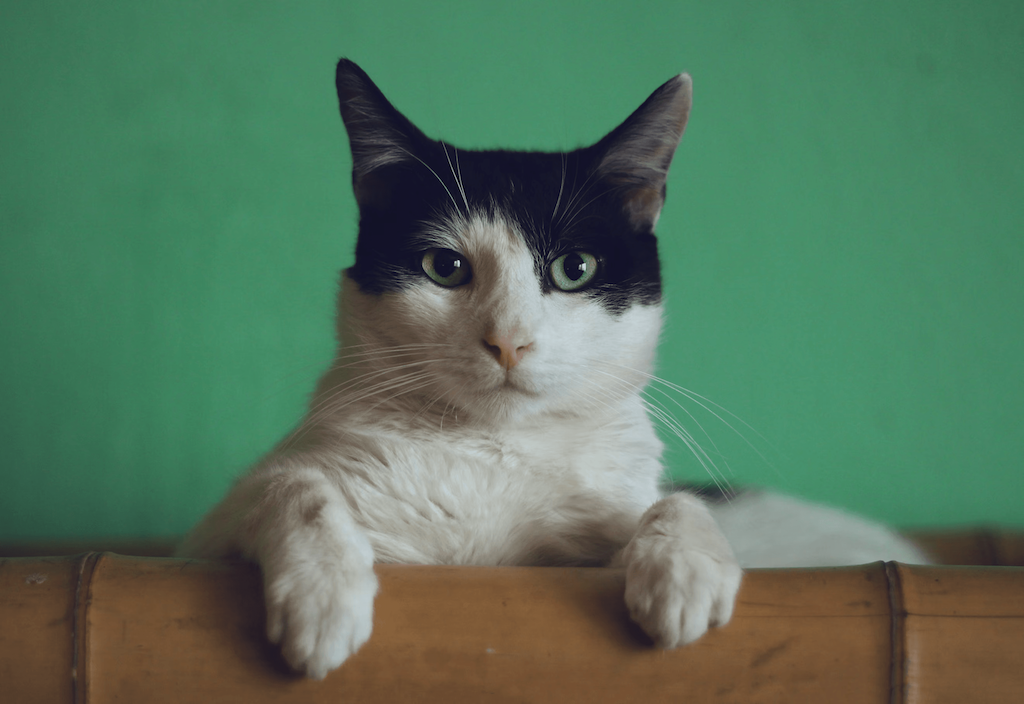

In [5]:
import os
from urllib.request import urlretrieve
import torch
from PIL import Image
from huggingface_hub import get_token
from huggingface_hub.utils import disable_progress_bars as disable_hf_progress
from diffusers.utils import logging as diffusers_logging
from transformers.utils import logging as transformers_logging

MODEL_ID = os.environ.get('WSM_NOTEBOOK_MODEL', 'World-Snapshot/WSM_v1')
BASE_MODEL = os.environ.get('WSM_NOTEBOOK_BASE_MODEL') or None
DEVICE = 'cuda:0'
OUTPUT_ROOT = Path(os.environ.get('WSM_NOTEBOOK_OUTPUT_ROOT', 'wsm-notebook-outputs'))
CACHE_DIR = os.environ.get('WSM_NOTEBOOK_CACHE') or None
INPUT_IMAGE = Path(os.environ.get('WSM_NOTEBOOK_INPUT', 'wsm-example-input.png'))
INPUT_URL = 'https://huggingface.co/datasets/huggingface/documentation-images/resolve/main/diffusers/cat.png'
STEPS, SEED, SIZE = 10, 20260812, 256

if not INPUT_IMAGE.is_file():
    urlretrieve(INPUT_URL, INPUT_IMAGE)
token = get_token()
if token is None:
    try:
        from google.colab import userdata
        token = userdata.get('HF_TOKEN')
    except Exception:
        token = None
disable_hf_progress()
diffusers_logging.disable_progress_bar()
transformers_logging.disable_progress_bar()
if token:
    os.environ.setdefault('HF_TOKEN', token)
else:
    print('No Hugging Face token detected; this is fine when the model repository is public.')
assert torch.cuda.is_available(), 'Real inference requires a CUDA-capable GPU.'
print('GPU:', torch.cuda.get_device_name(torch.cuda.current_device()))
display(Image.open(INPUT_IMAGE).convert('RGB'))

EXPERIMENTS = [
    {'name': 'rgb_to_normal', 'inputs': ['0-2'], 'output': '36-38', 'run': True},
    {'name': 'rgb_to_edge', 'inputs': ['0-2'], 'output': '40', 'run': True},
    {'name': 'rgb_to_curvature', 'inputs': ['0-2'], 'output': '39', 'run': True},
]

## 5. Run WSM

`from_pretrained` downloads only the selected task run and shared FLUX.2 backbone. `output_dir` retains the visualization, generated WSG tensor, and runtime manifest.

In [6]:
import gc, io, time
from contextlib import redirect_stderr, redirect_stdout
results = {}
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
for experiment in EXPERIMENTS:
    if not experiment['run']:
        continue
    print(f"\nRunning {experiment['name']}: {experiment['inputs']} -> {experiment['output']}")
    started = time.perf_counter()
    run_log = io.StringIO()
    try:
        with redirect_stdout(run_log), redirect_stderr(run_log):
            pipe = WSMPipeline.from_pretrained(
                MODEL_ID, inputs=experiment['inputs'], output=experiment['output'], base_model=BASE_MODEL,
                torch_dtype=torch.bfloat16, device=DEVICE, token=token, cache_dir=CACHE_DIR,
            )
            result = pipe(
                INPUT_IMAGE, num_inference_steps=STEPS, seed=SEED, size=SIZE,
                output_dir=OUTPUT_ROOT / experiment['name'], paper_demo=False,
            )
    except Exception:
        print(run_log.getvalue())
        raise
    stage_log = [line for line in run_log.getvalue().splitlines() if line.startswith('[WSM Inference]')]
    print('\n'.join(stage_log))
    reader_records = []
    for record in result.metadata['manifest']['outputs']:
        path = Path(record['path'])
        if 'wsg_reader_outputs' not in path.parts:
            continue
        reader_records.append({**record, 'image': Image.open(path).convert('RGB').copy()})
    if not reader_records:
        raise RuntimeError('Reader-only example received no WSG Reader visualizations')
    print(f"WSG Reader visualizations ({len(reader_records)}):")
    for record in reader_records:
        print(f"  - {record['label']} ({record['filename']})")
    results[experiment['name']] = {
        'reader_outputs': reader_records, 'task_id': result.task_id,
        'wsg_shape': None if result.wsg is None else result.wsg.shape,
        'seconds_including_load': time.perf_counter() - started,
        'artifacts': {name: str(path) for name, path in result.artifacts.items()},
    }
    del result, pipe
    gc.collect(); torch.cuda.empty_cache()
display(pd.DataFrame([
    {'experiment': name, 'task_id': r['task_id'], 'reader_views': len(r['reader_outputs']), 'generated_wsg_shape': r['wsg_shape'],
     'seconds_including_load': round(r['seconds_including_load'], 2)}
    for name, r in results.items()
]))


Running rgb_to_normal: ['0-2'] -> 36-38


[WSM Inference] Reading run configuration for <WSM_MODEL_REPOSITORY>/train_log/Channel_Head_000003/20260809_231823_q_20260809-161033/ckpt/0001780/pytorch_lora_weights.safetensors
[WSM Inference] Loading WSM training module
[WSM Inference] Initializing base model from /common/users/sf895/WSM_models/black-forest-labs/FLUX.2-klein-4B
[WSM Inference] Loading Channel Head checkpoint weights
[WSM Inference] No categorical refiner selected or available
[WSM Inference] Checkpoint format: safetensors
[WSM Inference] Input check GREEN 0-2: PNG · RGB input · 1024×704 · RGBA
[WSM Inference] Preparing 1 visual input(s) at 256 × 256
[WSM Inference] Encoding RGB input modality 0-2
[WSM Inference] Encoding text and modality prompt
[WSM Inference] Starting denoising with 10 step(s)
[WSM Inference] Denoising step 1/10
[WSM Inference] Denoising step 2/10
[WSM Inference] Denoising step 3/10
[WSM Inference] Denoising step 4/10
[WSM Inference] Denoising step 5/10
[WSM Inference] Denoising step 6/10
[WSM Inf


Running rgb_to_edge: ['0-2'] -> 40


[ WARN:0@32.722] global loadsave.cpp:1063 imwrite_ Unsupported depth image for selected encoder is fallbacked to CV_8U.


[WSM Inference] Reading run configuration for <WSM_MODEL_REPOSITORY>/train_log/Channel_Head_000005/20260809_231828_q_20260809-161033/ckpt/final_step_0002000/pytorch_lora_weights.safetensors
[WSM Inference] Loading WSM training module
[WSM Inference] Initializing base model from /common/users/sf895/WSM_models/black-forest-labs/FLUX.2-klein-4B
[WSM Inference] Loading Channel Head checkpoint weights
[WSM Inference] No categorical refiner selected or available
[WSM Inference] Checkpoint format: safetensors
[WSM Inference] Input check GREEN 0-2: PNG · RGB input · 1024×704 · RGBA
[WSM Inference] Preparing 1 visual input(s) at 256 × 256
[WSM Inference] Encoding RGB input modality 0-2
[WSM Inference] Encoding text and modality prompt
[WSM Inference] Starting denoising with 10 step(s)
[WSM Inference] Denoising step 1/10
[WSM Inference] Denoising step 2/10
[WSM Inference] Denoising step 3/10
[WSM Inference] Denoising step 4/10
[WSM Inference] Denoising step 5/10
[WSM Inference] Denoising step 6/


Running rgb_to_curvature: ['0-2'] -> 39


[WSM Inference] Reading run configuration for <WSM_MODEL_REPOSITORY>/train_log/Channel_Head_000004/20260809_231824_q_20260809-161033/ckpt/0001380/pytorch_lora_weights.safetensors
[WSM Inference] Loading WSM training module
[WSM Inference] Initializing base model from /common/users/sf895/WSM_models/black-forest-labs/FLUX.2-klein-4B
[WSM Inference] Loading Channel Head checkpoint weights
[WSM Inference] No categorical refiner selected or available
[WSM Inference] Checkpoint format: safetensors
[WSM Inference] Input check GREEN 0-2: PNG · RGB input · 1024×704 · RGBA
[WSM Inference] Preparing 1 visual input(s) at 256 × 256
[WSM Inference] Encoding RGB input modality 0-2
[WSM Inference] Encoding text and modality prompt
[WSM Inference] Starting denoising with 10 step(s)
[WSM Inference] Denoising step 1/10
[WSM Inference] Denoising step 2/10
[WSM Inference] Denoising step 3/10
[WSM Inference] Denoising step 4/10
[WSM Inference] Denoising step 5/10
[WSM Inference] Denoising step 6/10
[WSM Inf

,experiment,task_id,reader_views,generated_wsg_shape,seconds_including_load
0,rgb_to_normal,dense:0-2->36-38,6,"(256, 256, 256)",33.55
1,rgb_to_edge,dense:0-2->40,3,"(256, 256, 256)",29.74
2,rgb_to_curvature,dense:0-2->39,3,"(256, 256, 256)",29.20


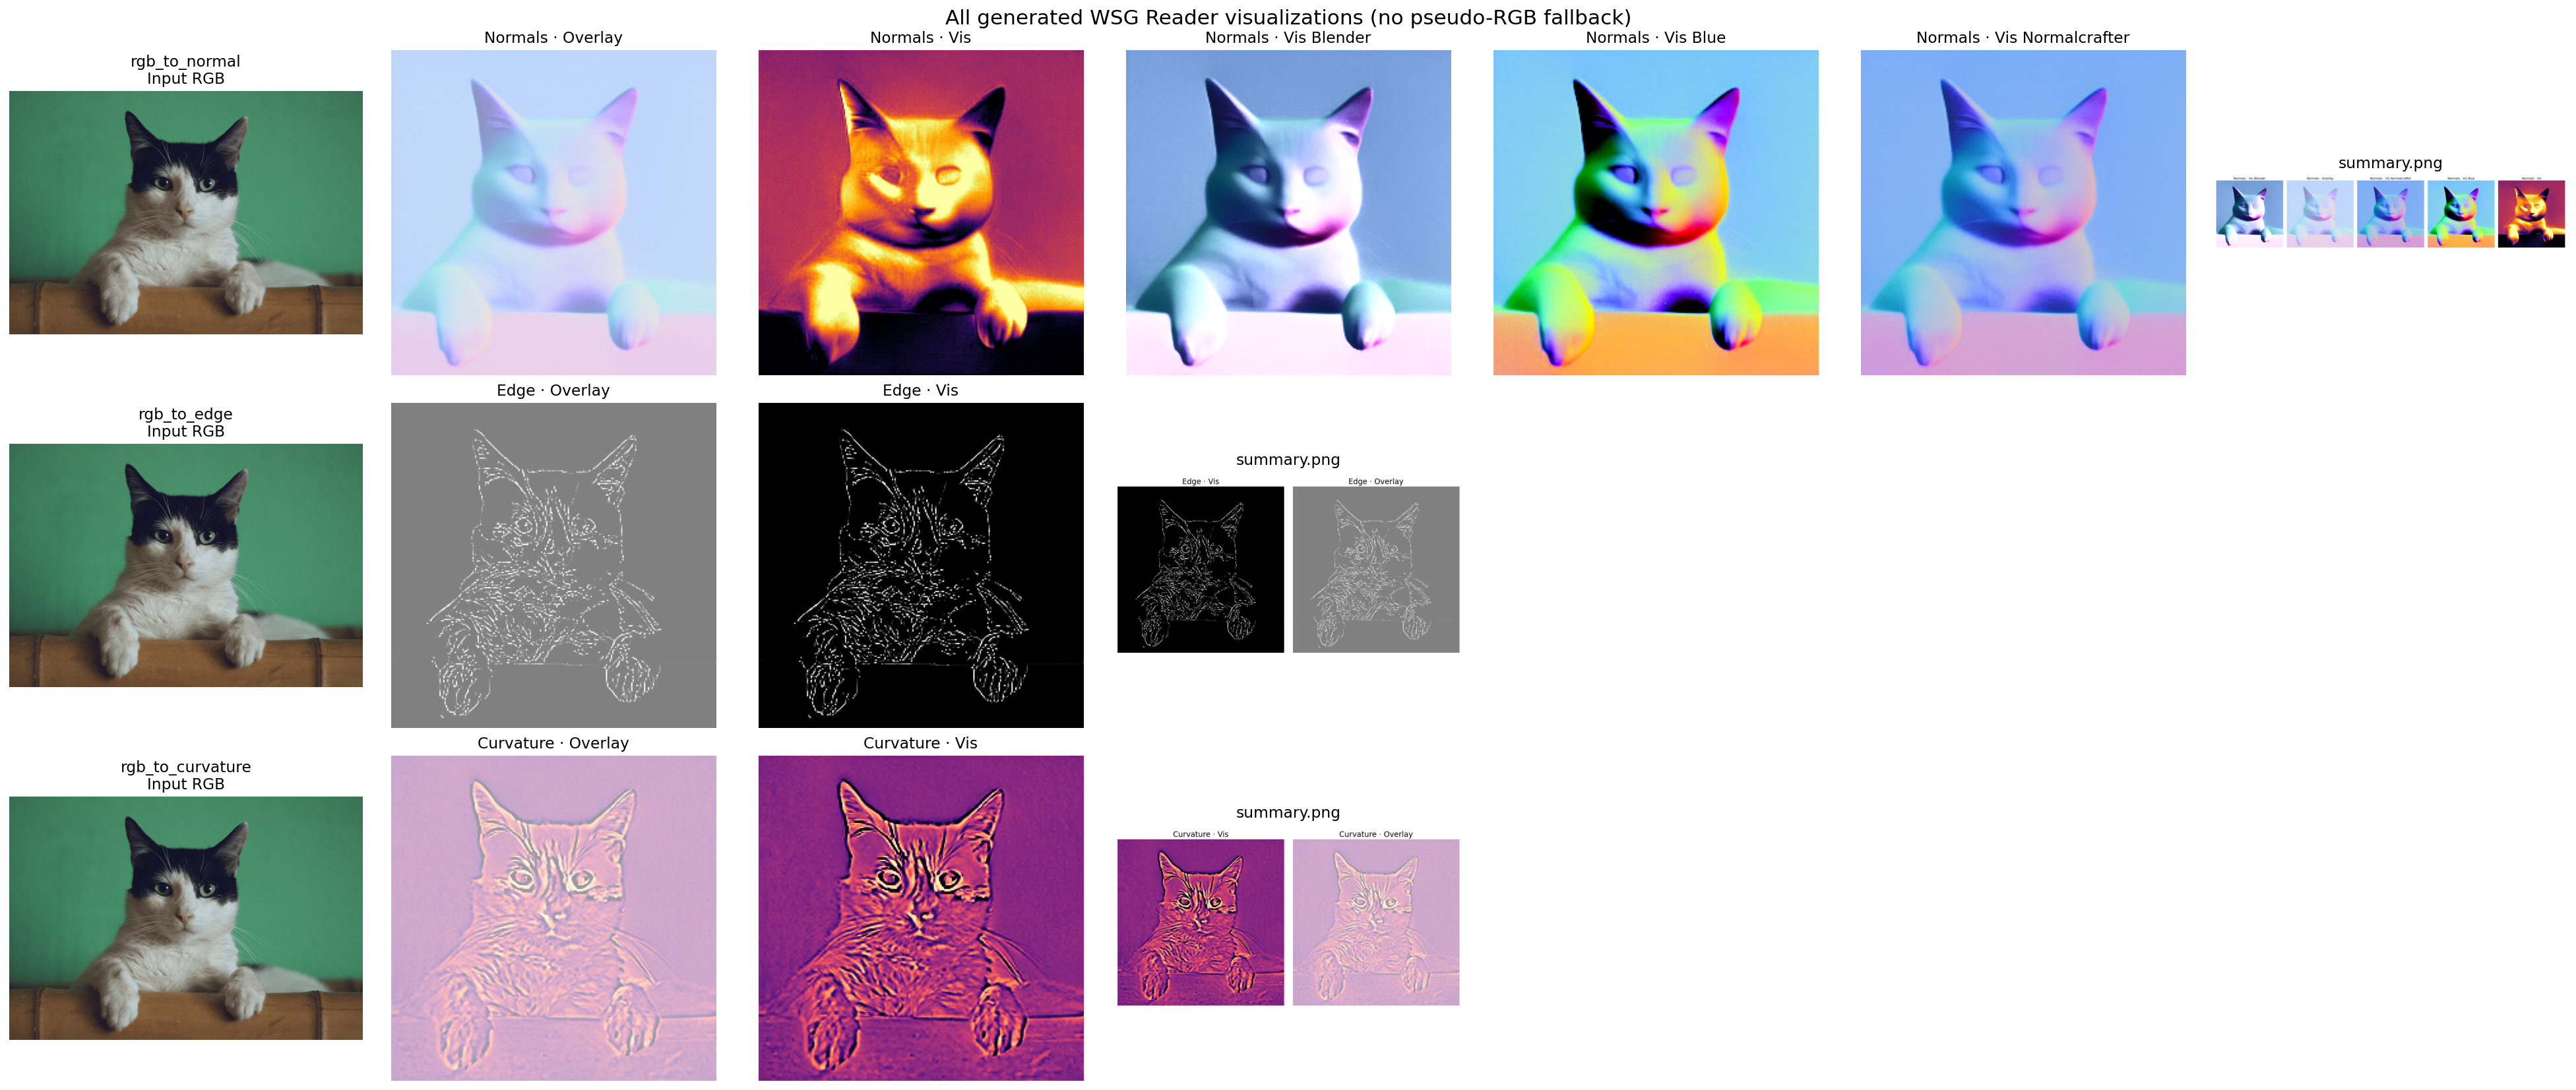

In [7]:
import matplotlib.pyplot as plt
from IPython.display import Image as DisplayImage
rows = len(results)
columns = 1 + max(len(record['reader_outputs']) for record in results.values())
figure, axes = plt.subplots(rows, columns, figsize=(4.0 * columns, 4.0 * rows), squeeze=False)
input_rgb = Image.open(INPUT_IMAGE).convert('RGB')
for row, (name, record) in enumerate(results.items()):
    axes[row, 0].imshow(input_rgb)
    axes[row, 0].set_title(f'{name}\nInput RGB')
    axes[row, 0].axis('off')
    for column, reader_output in enumerate(record['reader_outputs'], start=1):
        axes[row, column].imshow(reader_output['image'])
        axes[row, column].set_title(reader_output['label'])
        axes[row, column].axis('off')
    for column in range(1 + len(record['reader_outputs']), columns):
        axes[row, column].axis('off')
figure.suptitle('All generated WSG Reader visualizations (no pseudo-RGB fallback)', fontsize=16)
plt.tight_layout()
gallery_png = io.BytesIO()
figure.savefig(gallery_png, format='png', dpi=140, bbox_inches='tight')
display(DisplayImage(data=gallery_png.getvalue()))
plt.close(figure)

## 6. Multi-input, exact-Head, and CLI patterns

A multi-input tunnel accepts a modality-keyed dictionary. Non-RGB inputs use modality-scoped `.npz`/`.wsg.npz` files:

```python
pipe = WSMPipeline.from_pretrained(MODEL_ID, inputs=['39', '0-2'], output='90-92', device='cuda:0')
result = pipe({'39': 'curvature.npz', '0-2': 'reference.png'})
```

Pin an exact implementation only when reproducibility requires it:

```python
pipe = WSMPipeline.from_pretrained(MODEL_ID, head='dense:000003', device='cuda:0')
```

Equivalent command-line inference:

```bash
wsms infer --input 0-2=input.png --target 36-38 --steps 10 --seed 20260812 --output-dir outputs/rgb_to_normal
```

Use `wsms tunnel list` to discover mappings, `wsms head list` to inspect implementations, and `cache_dir=...` or `local_files_only=True` to control model storage.